# Label-free and label-efficient performance monitoring of breast ultrasound classifiers
Estimates the sensitivity, specificity and PPV of a breast ultrasound classifier at a new hospital
using no labels, a known cancer rate, or a small number of labelled cases.

**Runtime → Change runtime type → T4 GPU**, then run the cells from top to bottom.

| Cell | Step |
|---|---|
| 1 | Setup and configuration |
| 2 | Download and unpack the datasets |
| 3 | Library code (loaders, splits, classifier, estimators) |
| 4 | Build the image manifest (near-duplicate grouping, patient-level splits) |
| 5 | Extract embeddings with frozen pre-trained models (GPU) |
| 6 | Main experiment: label-free and prevalence-informed estimation |
| 7 | Few-label and unlabelled sample-size experiments |
| 8 | Tables and figures |
| 9 | Supplementary analyses |

All datasets are kept as zip files in Google Drive (`MyDrive/bus_data/raw/`) and are downloaded only once.
Every slow step saves a checkpoint to Drive, so after a disconnection simply run all cells again.

In [1]:
# ===== CELL 1: SETUP =====
!pip -q install open_clip_torch timm imagehash kagglehub openpyxl
import os, re, glob, zipfile, subprocess
from pathlib import Path

USE_DRIVE = True
if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        DRIVE_DIR = Path("/content/drive/MyDrive/bus_data")
    except ImportError:  # not in Colab
        DRIVE_DIR = Path("bus_data")
else:
    DRIVE_DIR = Path("bus_data")
DRIVE_DIR.mkdir(parents=True, exist_ok=True)
# Storage layout
#   Drive (permanent):  bus_data/raw/      downloaded zips  -> downloaded only ONCE, ever
#                       bus_data/work/     manifest + embeddings (checkpoints)
#                       bus_data/results/  per-model results (checkpoints), tables, figures
#   Colab disk (fast, wiped when the session ends): /content/data  <- zips are unpacked here each session
RAW = DRIVE_DIR / "raw"
DATA = Path("/content/data") if Path("/content").exists() else Path("data")
WORK = DRIVE_DIR / "work"
RESULTS = DRIVE_DIR / "results"
for p in (RAW, DATA, WORK, RESULTS):
    p.mkdir(parents=True, exist_ok=True)

CONFIG = dict(
    image_mode="roi",       # 'roi' = square crop around the lesion (default) | 'full'
    roi_margin=0.15,
    dedup_max_hamming=6,    # perceptual-hash distance for "same image"
    target_sens=0.90,       # operating point fixed on the source calibration set
    prev_grid=[0.1, 0.2, 0.3, 0.5, 0.7],
    reps=50, n_sub=100,     # prevalence stress test: 50 resamples of 100 cases
    models=["resnet50", "dinov2_b14", "clip_b16", "biomedclip"],  # add "medsiglip" if you have HF access
    # few-label extension: K labelled target cases (K=0 is the label-free method)
    few_k=[0, 5, 10, 20, 40, 80],
    prior_sd_a=0.5, prior_sd_b=1.0,   # base scale of the label-free prior (rescaled automatically by empirical Bayes)
    # sample-size extension: number of unlabelled target images available
    n_unlab=[25, 50, 100, 200, 400],
    reps_ext=50,
    # aggregate cancer rate known from hospital records, with this much error (absolute)
    known_prev_err=[0.05, 0.10],
    # untouched confirmation site: method design is frozen on the other sites, this one is evaluated once
    holdout="WHU",
    seed=0,
)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 23.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 15.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 3.3 MB/s eta 0:00:00
Mounted at /content/drive


In [2]:
# ===== CELL 2: DOWNLOAD DATA =====
# CHECKPOINT: every dataset is stored as a zip in Drive (bus_data/raw/). If the zip is already
# there it is NOT downloaded again; it is only unpacked to the fast local disk.
import shutil
import requests


def ok_zip(z: Path) -> bool:
    return z.exists() and zipfile.is_zipfile(z)


def wget(url: str, out: Path) -> bool:
    out.parent.mkdir(parents=True, exist_ok=True)
    tmp = out.with_suffix(out.suffix + ".part")
    r = subprocess.run(["wget", "-q", "-O", str(tmp), url])
    if r.returncode == 0 and tmp.stat().st_size > 0:
        tmp.rename(out)  # only a COMPLETE download gets the final name
        return True
    tmp.unlink(missing_ok=True)
    return False


def extract_nested(folder: Path):
    """Some datasets wrap the author's own zips inside the archive: unpack those too."""
    for _ in range(3):
        inner = [z for z in folder.rglob("*.zip") if not (z.parent / z.stem).exists()]
        if not inner:
            break
        for z in inner:
            try:
                with zipfile.ZipFile(z) as f:
                    f.extractall(z.parent / z.stem)
            except zipfile.BadZipFile:
                pass


def unpack(z: Path, dest: Path):
    """Drive zip -> local disk (skipped if already unpacked in this session)."""
    if dest.exists() and any(dest.rglob("*.*")):
        return
    print("unpacking", z.name, "->", dest)
    with zipfile.ZipFile(z) as f:
        f.extractall(dest)
    extract_nested(dest)


def mendeley_fetch(ds_id: str, version: int, z: Path) -> bool:
    """Mendeley Data: 'Download All' archive first, public API file-by-file as fallback."""
    dl = z.with_name(z.stem + ".download.zip")  # never overwrite/delete a file the user placed in raw/
    if wget(f"https://prod-dcd-datasets-cache-zipfiles.s3.eu-west-1.amazonaws.com/{ds_id}-{version}.zip", dl) and ok_zip(dl):
        os.replace(dl, z)
        return True
    dl.unlink(missing_ok=True)
    tmp = DATA / f"_tmp_{ds_id}"
    try:
        api = f"https://data.mendeley.com/public-api/datasets/{ds_id}"
        folders = {"root": tmp}
        r = requests.get(f"{api}/folders/{version}", timeout=60)
        if r.ok:
            info = {f["id"]: f for f in r.json()}

            def path_of(fid):
                f = info[fid]
                return (path_of(f["parent_id"]) if f.get("parent_id") in info else tmp) / f["name"]

            folders.update({fid: path_of(fid) for fid in info})
        n = 0
        for fid, local in folders.items():
            r = requests.get(f"{api}/files", params={"folder_id": fid, "version": version}, timeout=60)
            if not r.ok:
                continue
            for f in r.json():
                local.mkdir(parents=True, exist_ok=True)
                with requests.get(f["content_details"]["download_url"], stream=True, timeout=300) as d:
                    d.raise_for_status()
                    with open(local / f["filename"], "wb") as fh:
                        for chunk in d.iter_content(1 << 20):
                            fh.write(chunk)
                n += 1
        if n:
            shutil.make_archive(str(z.with_suffix("")), "zip", tmp)  # save to Drive as one zip
            shutil.rmtree(tmp, ignore_errors=True)
            return ok_zip(z)
    except Exception as e:
        print(f"  Mendeley API route failed for {ds_id}: {e}")
    shutil.rmtree(tmp, ignore_errors=True)
    return False


status = {}

# BUSI (Egypt) - public Kaggle mirror of Al-Dhabyani et al. 2020
z = RAW / "BUSI.zip"
if not ok_zip(z):
    try:
        import kagglehub
        p = kagglehub.dataset_download("aryashah2k/breast-ultrasound-images-dataset")
        shutil.make_archive(str(z.with_suffix("")), "zip", p)
    except Exception as e:
        print("BUSI download failed:", e)
status["BUSI"] = ok_zip(z)

# BUS-BRA (Brazil) - Zenodo, CC BY 4.0
z = RAW / "BUSBRA.zip"
if not ok_zip(z):
    wget("https://zenodo.org/records/8231412/files/BUSBRA.zip?download=1", z)
status["BUSBRA"] = ok_zip(z)

# BrEaST (Poland) - TCIA, CC BY 4.0: images+masks ZIP and clinical XLSX (labels) are separate files
TCIA = "https://www.cancerimagingarchive.net/wp-content/uploads/"
z, xl = RAW / "BrEaST.zip", RAW / "BrEaST-clinical.xlsx"
if not ok_zip(z):
    wget(TCIA + "BrEaST-Lesions_USG-images_and_masks-Dec-15-2023.zip", z)
if not xl.exists():
    wget(TCIA + "BrEaST-Lesions-USG-clinical-data-Dec-15-2023.xlsx", xl)
status["BrEaST"] = ok_zip(z) and xl.exists()

# BUS-UCLM (Spain) and BUSI_WHU (China) - Mendeley Data, version 3
for name, ds_id in (("UCLM", "7fvgj4jsp7"), ("WHU", "k6cpmwybk3")):
    z = RAW / f"{name}.zip"
    if not ok_zip(z):  # a manually downloaded zip with another name (e.g. 'UCLM.zip.zip', '7fvgj4jsp7-3.zip')?
        keys = [name.lower(), ds_id]
        for f in sorted(set(RAW.glob("*")) | set(DRIVE_DIR.glob("*.zip"))):
            if f.is_file() and f != z and any(k in f.name.lower() for k in keys) and ok_zip(f):
                shutil.copy(f, z)
                print(f"{name}: using manually downloaded '{f.name}'")
                break
    if not ok_zip(z):
        mendeley_fetch(ds_id, 3, z)
    status[name] = ok_zip(z)
    if not status[name]:
        print(f"{name}: AUTO-DOWNLOAD FAILED -> click 'Download All' on https://data.mendeley.com/datasets/{ds_id}/3,"
              f" rename the file to {name}.zip and put it in {RAW}")

# unpack everything that is in Drive to the local disk
for name, ok in status.items():
    if ok:
        unpack(RAW / f"{name}.zip", DATA / name)
if status["BrEaST"]:
    shutil.copy(RAW / "BrEaST-clinical.xlsx", DATA / "BrEaST" / "BrEaST-clinical.xlsx")

DATASET_PATHS = {k: (str(DATA / k) if v else None) for k, v in status.items()}
print("\n".join(f"  {k:7s} {'OK  ' + v if v else 'MISSING'}" for k, v in DATASET_PATHS.items()))


unpacking BUSI.zip -> /content/data/BUSI
unpacking BUSBRA.zip -> /content/data/BUSBRA
unpacking BrEaST.zip -> /content/data/BrEaST
unpacking UCLM.zip -> /content/data/UCLM
unpacking WHU.zip -> /content/data/WHU
  BUSI    OK  /content/data/BUSI
  BUSBRA  OK  /content/data/BUSBRA
  BrEaST  OK  /content/data/BrEaST
  UCLM    OK  /content/data/UCLM
  WHU     OK  /content/data/WHU


In [3]:
# ===== CELL 3: LIBRARY CODE =====
import re
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image

IMG_EXT = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}
COLUMNS = ["uid", "dataset", "image_path", "mask_paths", "label", "patient_id", "device"]


def inspect(root, n=4):
    """print folder tree - use this if a loader complains"""
    root = Path(root)
    seen = {}
    for p in sorted(root.rglob("*")):
        if p.is_file():
            seen.setdefault(p.parent, []).append(p.name)
    for d, fs in seen.items():
        print(f"{d.relative_to(root)}/ ({len(fs)} files):", fs[:n])


def _all_images(root):
    return sorted(p for p in Path(root).rglob("*") if p.is_file() and p.suffix.lower() in IMG_EXT)


def _find_dir(root, name):
    c = [p for p in Path(root).rglob("*") if p.is_dir() and p.name.lower() == name.lower()]
    return min(c, key=lambda p: len(p.parts)) if c else None


def _label(s):
    s = str(s).strip().lower()
    return 1 if s.startswith("malig") else 0 if s.startswith("benig") else None


def _frame(rows, name):
    df = pd.DataFrame(rows, columns=COLUMNS)
    if df.empty:
        raise RuntimeError(f"[{name}] no images found - run inspect(path) and check the layout")
    print(f"[{name}] {len(df)} lesion images | malignant={int(df.label.sum())} benign={int((df.label == 0).sum())}"
          f" | patient IDs: {(df.patient_id != '').mean():.0%} | masks: {(df.mask_paths != '').mean():.0%}")
    return df


def load_busi(root):
    """Dataset_BUSI_with_GT/{benign,malignant,normal}/'benign (1).png' + 'benign (1)_mask.png'"""
    rows = []
    for cls in ("benign", "malignant"):
        d = _find_dir(root, cls)
        if d is None:
            raise FileNotFoundError(f"BUSI: folder '{cls}' not found under {root}")
        files = {p.name: p for p in d.iterdir()}
        for p in sorted(d.iterdir()):
            if p.suffix.lower() not in IMG_EXT or "_mask" in p.stem:
                continue
            masks = sorted(str(q) for n, q in files.items() if n.startswith(p.stem + "_mask"))
            rows.append(dict(uid=f"BUSI/{cls}/{p.stem}", dataset="BUSI", image_path=str(p),
                             mask_paths=";".join(masks), label=int(cls == "malignant"), patient_id="", device=""))
    return _frame(rows, "BUSI")


def load_busbra(root):
    """BUSBRA/Images/bus_0001-l.png, BUSBRA/Masks/mask_0001-l.png, bus_data.csv (ID, Case, Pathology, Device)"""
    csv = list(Path(root).rglob("bus_data.csv"))
    if not csv:
        raise FileNotFoundError("BUS-BRA: bus_data.csv not found")
    base, meta = csv[0].parent, pd.read_csv(csv[0])
    imgs = {p.stem: p for p in _all_images(_find_dir(base, "Images") or base)}
    mdir = _find_dir(base, "Masks")
    msks = {re.sub(r"^mask_?", "", p.stem): p for p in _all_images(mdir)} if mdir else {}
    has_case, has_dev = "Case" in meta.columns, "Device" in meta.columns
    if not has_case:
        print("[BUSBRA] no 'Case' column: patient grouping falls back to image hashing")
    rows = []
    for _, r in meta.iterrows():
        sid, lab = str(r["ID"]), _label(r["Pathology"])
        if lab is None or sid not in imgs:
            continue
        key = re.sub(r"^bus_?", "", sid)
        rows.append(dict(uid=f"BUSBRA/{sid}", dataset="BUSBRA", image_path=str(imgs[sid]),
                         mask_paths=str(msks[key]) if key in msks else "", label=lab,
                         patient_id=f"BUSBRA_{r['Case']}" if has_case else "",
                         device=str(r["Device"]) if has_dev else ""))
    return _frame(rows, "BUSBRA")


def load_uclm(root):
    """images/XXXX_000.png + masks/XXXX_000.png; RGB mask red=malignant, green=benign, black=normal.
    Patient = filename prefix before '_'. Only 38 patients -> patient-level splits are essential."""
    idir, mdir = _find_dir(root, "images"), _find_dir(root, "masks")
    if idir is None or mdir is None:
        raise FileNotFoundError("BUS-UCLM: expected 'images' and 'masks' folders")
    msks = {p.name: p for p in _all_images(mdir)}
    rows = []
    for p in _all_images(idir):
        m = msks.get(p.name)
        if m is None:
            continue
        a = np.asarray(Image.open(m).convert("RGB")).astype(int)
        red = ((a[..., 0] > 127) & (a[..., 1] < 100)).sum()
        green = ((a[..., 1] > 127) & (a[..., 0] < 100)).sum()
        if red == 0 and green == 0:
            continue  # normal tissue image
        rows.append(dict(uid=f"UCLM/{p.stem}", dataset="UCLM", image_path=str(p), mask_paths=str(m),
                         label=int(red > green), patient_id="UCLM_" + p.stem.split("_")[0], device="Siemens S2000"))
    return _frame(rows, "UCLM")


def load_breast(root):
    """TCIA BrEaST: xlsx with Case_ID, Image_filename, Mask_tumor_filename, Classification"""
    xl = [p for p in Path(root).rglob("*.xlsx") if not p.name.startswith("~")]
    if not xl:
        raise FileNotFoundError("BrEaST: clinical .xlsx not found")
    meta = pd.read_excel(xl[0])
    files = {p.name: p for p in _all_images(root)}
    rows = []
    for _, r in meta.iterrows():
        lab, fn = _label(r.get("Classification", "")), str(r.get("Image_filename", "")).strip()
        if lab is None or fn not in files:
            continue
        names = [s.strip() for s in re.split(r"[&;,]", str(r.get("Mask_tumor_filename", ""))) if s.strip()]
        masks = [str(files[n]) for n in names if n in files] or \
                [str(p) for n, p in files.items() if n.startswith(Path(fn).stem + "_tumor")]
        rows.append(dict(uid=f"BrEaST/{Path(fn).stem}", dataset="BrEaST", image_path=str(files[fn]),
                         mask_paths=";".join(masks), label=lab,
                         patient_id=f"BrEaST_{r.get('Case_ID', Path(fn).stem)}", device=""))
    return _frame(rows, "BrEaST")


MASK_HINT = re.compile(r"(mask|label|annot|gt|seg)", re.I)


def load_generic(root, name):
    """.../<benign|malignant>/... ; mask = file/folder containing mask|label|gt, matched by stem.
    CHECK the printed counts against the dataset description."""
    root = Path(root)
    images, masks = [], {}
    for p in _all_images(root):
        if MASK_HINT.search(str(p.relative_to(root))):
            stem = re.sub(r"(_?mask|_?label|_?gt|_?seg)\w*$", "", p.stem, flags=re.I)
            masks.setdefault(stem, []).append(str(p))
        else:
            images.append(p)
    rows = []
    for p in images:
        parts = [s.lower() for s in p.relative_to(root).parts]
        lab = 1 if any(s.startswith("malig") for s in parts) else 0 if any(s.startswith("benig") for s in parts) else None
        if lab is not None:
            rows.append(dict(uid=f"{name}/{p.relative_to(root).with_suffix('')}", dataset=name, image_path=str(p),
                             mask_paths=";".join(masks.get(p.stem, [])), label=lab, patient_id="", device=""))
    return _frame(rows, name)


def load_whu(root):
    """BUSI-WHU: img/00001.bmp + gt/00001_anno.bmp; labels in Patient_infos_BUSI-WHU.xlsx,
    column 'Benign(0)\nmalignant(1)' (0 = benign, 1 = malignant), image name in 'img_names'."""
    xl = [p for p in Path(root).rglob("Patient_infos*.xlsx") if not p.name.startswith("~")]
    if not xl:
        raise FileNotFoundError("WHU: Patient_infos*.xlsx not found")
    meta = pd.read_excel(xl[0])
    lab_col = [c for c in meta.columns if "malignant" in str(c).lower()][0]
    idir, gdir = _find_dir(root, "img"), _find_dir(root, "gt")
    if idir is None or gdir is None:
        raise FileNotFoundError("WHU: expected 'img' and 'gt' folders")
    imgs = {p.name: p for p in _all_images(idir)}
    gts = {p.stem.replace("_anno", ""): p for p in _all_images(gdir)}
    rows = []
    for _, r in meta.iterrows():
        fn = str(r["img_names"]).strip()
        if fn not in imgs or int(r[lab_col]) not in (0, 1):
            continue
        stem = Path(fn).stem
        rows.append(dict(uid=f"WHU/{stem}", dataset="WHU", image_path=str(imgs[fn]),
                         mask_paths=str(gts[stem]) if stem in gts else "", label=int(r[lab_col]),
                         patient_id=f"WHU_{r['patient_index']}", device=""))
    return _frame(rows, "WHU")


LOADERS = {"BUSI": load_busi, "BUSBRA": load_busbra, "UCLM": load_uclm, "BrEaST": load_breast, "WHU": load_whu}


def prepare_image(image_path, mask_paths, mode="roi", margin=0.15):
    """grayscale -> (optional) square lesion crop -> RGB"""
    img = Image.open(image_path).convert("L")
    if mode == "roi" and mask_paths:
        m = np.zeros((img.height, img.width), bool)
        for mp in mask_paths.split(";"):
            a = np.asarray(Image.open(mp).convert("RGB")).max(axis=2)
            a = a > (127 if a.max() > 1 else 0)  # masks may be stored as 0/255 or 0/1
            if a.shape != m.shape:
                a = np.asarray(Image.fromarray(a).resize((img.width, img.height), Image.NEAREST))
            m |= a
        if m.any():
            ys, xs = np.where(m)
            cy, cx = (ys.min() + ys.max()) / 2, (xs.min() + xs.max()) / 2
            side = max(max(ys.max() - ys.min(), xs.max() - xs.min()) * (1 + 2 * margin), 32)
            img = img.crop((int(cx - side / 2), int(cy - side / 2), int(cx + side / 2), int(cy + side / 2)))
    return img.convert("RGB")


# ---------- near-duplicates + patient-level splits ----------
def phash64(path):
    import imagehash
    return int(str(imagehash.phash(Image.open(path).convert("L"), hash_size=8)), 16)


def assign_groups(df, max_dist=6):
    """Same patient OR near-identical image (pHash) -> same group. Splits are made by group,
    so copies of one lesion can never be in both train and test (BUSI has many duplicates)."""
    df = df.reset_index(drop=True).copy()
    print(f"hashing {len(df)} images ...")
    H = np.array([phash64(p) for p in df.image_path], dtype=np.uint64)
    df["phash"] = [format(int(h), "016x") for h in H]
    parent = list(range(len(df)))

    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    for _, idx in df[df.patient_id != ""].groupby("patient_id").groups.items():
        idx = list(idx)
        for j in idx[1:]:
            parent[find(j)] = find(idx[0])
    pairs = []
    for i in range(len(df) - 1):
        d = np.unpackbits((H[i] ^ H[i + 1:]).view(np.uint8).reshape(-1, 8), axis=1).sum(1)
        for k in np.nonzero(d <= max_dist)[0]:
            j = i + 1 + int(k)
            parent[find(j)] = find(i)
            pairs.append((df.uid[i], df.uid[j], int(d[k]), df.label[i], df.label[j]))
    df["group_id"] = [f"g{find(i)}" for i in range(len(df))]
    dup = pd.DataFrame(pairs, columns=["uid_a", "uid_b", "hamming", "label_a", "label_b"])
    n_cross = (dup.uid_a.str.split("/").str[0] != dup.uid_b.str.split("/").str[0]).sum()
    print(f"near-duplicate pairs: {len(dup)} (cross-dataset {n_cross}, label conflicts {(dup.label_a != dup.label_b).sum()})")
    return df, dup


def make_splits(df, seed=0):
    """per dataset, group-aware & label-stratified: 60% train / 20% cal / 20% test"""
    from sklearn.model_selection import StratifiedGroupKFold
    df = df.copy()
    df["split"] = ""
    names = ["train", "train", "train", "cal", "test"]
    for ds, sub in df.groupby("dataset"):
        sg = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
        for f, (_, te) in enumerate(sg.split(sub, sub.label, sub.group_id)):
            df.loc[sub.index[te], "split"] = names[f]
    return df


# ---------- linear probe + calibration + frozen operating point ----------
from scipy.optimize import minimize_scalar
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, roc_auc_score
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def _sig(z):
    return 1 / (1 + np.exp(-np.clip(z, -50, 50)))


class Probe:
    def __init__(self, pipe):
        self.pipe, self.T, self.threshold = pipe, 1.0, 0.5

    def predict_proba(self, X):
        return _sig(self.pipe.decision_function(X) / self.T)


def build_probe(X_tr, y_tr, g_tr, X_cal, y_cal, target_sens=0.90, Cs=(1e-3, 1e-2, 1e-1, 1.0)):
    """1) logistic regression (C by group CV)  2) temperature scaling on 'cal'
       3) threshold on 'cal' giving >= target_sens sensitivity; then FROZEN like a deployed device"""
    cv = GroupKFold(int(min(5, len(np.unique(g_tr)))))
    best = min(Cs, key=lambda C: log_loss(y_tr, np.clip(cross_val_predict(
        make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=5000)), X_tr, y_tr,
        groups=g_tr, cv=cv, method="predict_proba")[:, 1], 1e-6, 1 - 1e-6)))
    pr = Probe(make_pipeline(StandardScaler(), LogisticRegression(C=best, max_iter=5000)).fit(X_tr, y_tr))
    z = pr.pipe.decision_function(X_cal)

    def nll(lt):
        p = np.clip(_sig(z / np.exp(lt)), 1e-7, 1 - 1e-7)
        return -np.mean(y_cal * np.log(p) + (1 - y_cal) * np.log(1 - p))

    pr.T = float(np.exp(minimize_scalar(nll, bounds=(-3, 3), method="bounded").x))
    pos = np.sort(pr.predict_proba(X_cal)[y_cal == 1])
    pr.threshold = float(pos[int(np.floor((1 - target_sens) * len(pos)))])
    return pr


# ---------- label-free performance estimators ----------
METRICS = ["sens", "spec", "ppv", "npv", "bacc", "acc", "auroc", "prev"]
EPS = 1e-9


def cm_metrics(tp, fp, tn, fn):
    se, sp, n = tp / (tp + fn + EPS), tn / (tn + fp + EPS), tp + fp + tn + fn
    return dict(sens=se, spec=sp, ppv=tp / (tp + fp + EPS), npv=tn / (tn + fn + EPS),
                bacc=(se + sp) / 2, acc=(tp + tn) / (n + EPS), prev=(tp + fn) / (n + EPS))


def true_metrics(p, y, t):
    yh, y = p >= t, y.astype(bool)
    m = cm_metrics(np.sum(yh & y), np.sum(yh & ~y), np.sum(~yh & ~y), np.sum(~yh & y))
    m["auroc"] = roc_auc_score(y, p) if 0 < y.sum() < len(y) else np.nan
    return m


def expected_auroc(score, q):
    """E[AUROC] if case i is malignant with prob q_i. O(n log n), ties get half credit."""
    o = np.argsort(score, kind="mergesort")
    s, q = score[o], q[o]
    neg = 1 - q
    _, inv, cnt = np.unique(s, return_inverse=True, return_counts=True)
    start = np.concatenate([[0], np.cumsum(cnt)[:-1]])[inv]
    below = np.concatenate([[0], np.cumsum(neg)])[start]
    tie = np.bincount(inv, weights=neg)[inv] - neg
    num = np.sum(q * (below + 0.5 * tie))
    den = q.sum() * neg.sum() - np.sum(q * neg)
    return float(num / (den + EPS))


def adjust(p, pi_s, pi_t):
    """Bayes re-weighting of P(malignant|x) from source to target prevalence"""
    a, b = p * pi_t / pi_s, (1 - p) * (1 - pi_t) / (1 - pi_s)
    return a / (a + b + EPS)


def prior_em(p, pi_s, iters=1000, tol=1e-6):
    """Saerens et al. 2002"""
    pi = pi_s
    for _ in range(iters):
        new = float(np.mean(adjust(p, pi_s, pi)))
        if abs(new - pi) < tol:
            break
        pi = new
    return float(np.clip(pi, 0.005, 0.995))


def prior_bbse(p_s, y_s, p_t, t):
    """Lipton et al. 2018, binary closed form"""
    tpr, fpr = np.mean(p_s[y_s == 1] >= t), np.mean(p_s[y_s == 0] >= t)
    return float(np.clip((np.mean(p_t >= t) - fpr) / (tpr - fpr + EPS), 0.005, 0.995))


def est_cbpe(p_t, t, q=None):
    q = p_t if q is None else q
    yh = p_t >= t
    m = cm_metrics(np.sum(q * yh), np.sum((1 - q) * yh), np.sum((1 - q) * ~yh), np.sum(q * ~yh))
    m["auroc"] = expected_auroc(p_t, q)
    return m


def _side(p, t, side):
    return (p >= t) if side else (p < t)


def est_atc(p_s, y_s, p_t, t):
    """CM-ATC (Garg et al. 2022; Fluhmann et al. 2025): one confidence threshold per predicted class"""
    v = []
    for side in (1, 0):
        ms, mt = _side(p_s, t, side), _side(p_t, t, side)
        cs = p_s[ms] if side else 1 - p_s[ms]
        ct = p_t[mt] if side else 1 - p_t[mt]
        if len(cs) == 0 or len(ct) == 0:
            v.append(np.nan)
            continue
        corr = np.mean(y_s[ms] == side)
        v.append(1.0 if corr >= 1 else float(np.mean(ct > np.quantile(cs, 1 - corr))))
    npp, nnp = np.sum(p_t >= t), np.sum(p_t < t)
    m = cm_metrics(v[0] * npp, (1 - v[0]) * npp, v[1] * nnp, (1 - v[1]) * nnp)
    m["auroc"] = np.nan
    return m


def est_doc(p_s, y_s, p_t, t):
    """Difference of Confidences (Guillory et al. 2021), per predicted class"""
    v = []
    for side in (1, 0):
        ms, mt = _side(p_s, t, side), _side(p_t, t, side)
        if ms.sum() == 0 or mt.sum() == 0:
            v.append(np.nan)
            continue
        c = (lambda p: p) if side else (lambda p: 1 - p)
        v.append(float(np.clip(np.mean(y_s[ms] == side) - (c(p_s[ms]).mean() - c(p_t[mt]).mean()), 0, 1)))
    npp, nnp = np.sum(p_t >= t), np.sum(p_t < t)
    m = cm_metrics(v[0] * npp, (1 - v[0]) * npp, v[1] * nnp, (1 - v[1]) * nnp)
    m["auroc"] = np.nan
    return m


def run_all(p_s, y_s, p_t, t, true_prev, known_err=(0.05, 0.10)):
    """Label-free estimators (no target labels) + prevalence-known variants (one aggregate number,
    e.g. from the hospital's pathology records, given exactly or with +/- error)."""
    pi_s = float(np.mean(y_s))
    out = {
        "source": true_metrics(p_s, y_s, t),                       # "nothing changed"
        "CBPE": est_cbpe(p_t, t),
        "ATC": est_atc(p_s, y_s, p_t, t),
        "DoC": est_doc(p_s, y_s, p_t, t),
        "PA-CBPE-EM": est_cbpe(p_t, t, adjust(p_t, pi_s, prior_em(p_t, pi_s))),            # prevalence estimated (EM)
        "PA-CBPE-BBSE": est_cbpe(p_t, t, adjust(p_t, pi_s, prior_bbse(p_s, y_s, p_t, t))),  # prevalence estimated (BBSE)
        "PA-CBPE-known(exact)": est_cbpe(p_t, t, adjust(p_t, pi_s, true_prev)),
    }
    for e in known_err:
        for sign, tag in ((1, "+"), (-1, "-")):
            pk = float(np.clip(true_prev + sign * e, 0.01, 0.99))
            out[f"PA-CBPE-known({tag}{round(100 * e)})"] = est_cbpe(p_t, t, adjust(p_t, pi_s, pk))
    return out


# ---------- few-label estimators: K labelled target cases + the unlabelled target pool ----------
from scipy.optimize import minimize


def _logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))


def est_labels_only(p_l, y_l, t, a=0.5):
    """Classical estimate from the K labelled cases alone (Jeffreys smoothing a=0.5 so it is always defined)."""
    yh, y = p_l >= t, y_l.astype(bool)
    tp, fp, tn, fn = np.sum(yh & y) + a, np.sum(yh & ~y) + a, np.sum(~yh & ~y) + a, np.sum(~yh & y) + a
    m = cm_metrics(tp, fp, tn, fn)
    m["auroc"] = roc_auc_score(y, p_l) if 0 < y.sum() < len(y) else np.nan
    return m


def est_ppi(p_u, q_u, p_l, q_l, y_l, t):
    """Prediction-powered inference (Angelopoulos et al., Science 2023): label-free predictions on the
    unlabelled pool + a bias correction measured on the K labelled cases. Unbiased for each expectation."""
    def parts(p, yy):
        yh = (p >= t).astype(float)
        return np.stack([yy, yy * yh, (1 - yy) * (1 - yh)], 1)  # E[y], E[TP], E[TN]
    e = parts(p_u, q_u).mean(0) + (parts(p_l, y_l.astype(float)) - parts(p_l, q_l)).mean(0)
    pos, tp, tn = np.clip(e, 1e-6, 1)
    pp = np.mean(np.concatenate([p_u, p_l]) >= t)  # positive-prediction rate is known exactly
    se, sp = min(tp / pos, 1), min(tn / max(1 - pos, 1e-6), 1)
    m = dict(sens=se, spec=sp, ppv=min(tp / max(pp, 1e-6), 1), npv=min(tn / max(1 - pp, 1e-6), 1),
             bacc=(se + sp) / 2, acc=min(tp + tn, 1), prev=pos, auroc=np.nan)
    return m


def _map_fit(z_l, y_l, b0, sd_a, sd_b):
    def obj(w):
        u = w[0] * z_l + w[1]
        return np.sum(np.logaddexp(0, u) - y_l * u) + (w[0] - 1) ** 2 / (2 * sd_a ** 2) + (w[1] - b0) ** 2 / (2 * sd_b ** 2)
    r = minimize(obj, x0=[1.0, b0], method="L-BFGS-B", bounds=[(0.05, 5), (-10, 10)])
    return r.x, r.fun


def recalibrate(z_l, y_l, b0, sd_a, sd_b, scales=(0.25, 0.5, 1, 2, 4, 16)):
    """Empirical-Bayes recalibration. Model: P(y=1|x) = sigmoid(a*z + b), prior a ~ N(1, (c*sd_a)^2),
    b ~ N(b0, (c*sd_b)^2), centred on the LABEL-FREE solution (b0 = estimated prevalence shift).
    The prior scale c is chosen by maximising the Laplace-approximated marginal likelihood (evidence)
    of the K labels (MacKay 1992): if the labels agree with the label-free estimate the prior stays tight,
    if they contradict it the prior relaxes. K=0 returns exactly the label-free solution (a=1, b=b0)."""
    if len(y_l) == 0:
        return 1.0, b0
    X = np.stack([z_l, np.ones_like(z_l)], 1)
    best, best_w = -np.inf, (1.0, b0)
    for c in scales:
        sa, sb = c * sd_a, c * sd_b
        w, neg_log_post = _map_fit(z_l, y_l, b0, sa, sb)
        pr = _sig(X @ w)
        H = (X * (pr * (1 - pr))[:, None]).T @ X + np.diag([1 / sa ** 2, 1 / sb ** 2])
        # log evidence = log p(y|w*) + log p(w*) + (d/2) log 2pi - 1/2 log|H|   (d = 2)
        log_ev = -neg_log_post - np.log(2 * np.pi * sa * sb) + np.log(2 * np.pi) - 0.5 * np.linalg.slogdet(H)[1]
        if log_ev > best:
            best, best_w = log_ev, w
    return best_w


def est_recal(p_all, lab_idx, y_l, t, b0, sd_a, sd_b):
    """Recalibrate on the labelled cases, then CBPE over the whole target (true labels used where known)."""
    if sd_a >= 10:  # flat prior: plain maximum-likelihood Platt scaling (ablation)
        a, b = _map_fit(_logit(p_all[lab_idx]), y_l, b0, sd_a, sd_b)[0] if len(y_l) else (1.0, b0)
    else:
        a, b = recalibrate(_logit(p_all[lab_idx]), y_l, b0, sd_a, sd_b)
    q = _sig(a * _logit(p_all) + b)
    q[lab_idx] = y_l
    return est_cbpe(p_all, t, q)


def few_label_all(p_s, y_s, p_t, lab_idx, y_l, t, sd_a=0.5, sd_b=1.0):
    """All few-label estimators for one draw of K labelled cases (lab_idx indexes p_t).
    Design decision (made on the development sites, confirmed on the held-out site): the Bayesian prior
    is centred on CBPE (a=1, b=0), the best label-free estimator; centring on the EM prevalence estimate
    is kept as an ablation."""
    pi_s = float(np.mean(y_s))
    unl = np.setdiff1d(np.arange(len(p_t)), lab_idx)
    b_em = float(_logit(np.array(prior_em(p_t, pi_s))) - _logit(np.array(pi_s)))
    out = {"BayesRecal (proposed)": est_recal(p_t, lab_idx, y_l, t, 0.0, sd_a, sd_b),
           "BayesRecal from PA-CBPE (ablation)": est_recal(p_t, lab_idx, y_l, t, b_em, sd_a, sd_b)}
    if len(lab_idx):
        out["labels-only"] = est_labels_only(p_t[lab_idx], y_l, t)
        out["PPI"] = est_ppi(p_t[unl], p_t[unl], p_t[lab_idx], p_t[lab_idx], y_l, t)  # CBPE posteriors as proxy
        out["Platt-K (no prior)"] = est_recal(p_t, lab_idx, y_l, t, 0.0, 10.0, 10.0)
    return out


print("library loaded")


library loaded


In [4]:
# ===== CELL 4: BUILD MANIFEST =====
# CHECKPOINT: the manifest (with duplicate groups and splits) is saved to Drive and reused, as long as
# the same datasets are present. Adding a dataset later triggers a rebuild automatically.
available = sorted(k for k, v in DATASET_PATHS.items() if v)
mf = WORK / "manifest.csv"
if mf.exists() and sorted(pd.read_csv(mf, usecols=["dataset"]).dataset.unique()) == available:
    manifest = pd.read_csv(mf, keep_default_na=False)
    # paths point to /content/data, which is rebuilt identically each session
    print("manifest checkpoint found ->", len(manifest), "images; skipping rebuild")
else:
    frames = []
    for name in available:
        try:
            frames.append(LOADERS[name](DATASET_PATHS[name]))
        except Exception as e:
            print(f"!! {name} failed: {e}\n   run inspect(DATASET_PATHS['{name}']) to see the folder layout")
    assert len(frames) >= 2, "need at least two datasets"
    manifest = pd.concat(frames, ignore_index=True)
    manifest, dups = assign_groups(manifest, CONFIG["dedup_max_hamming"])
    manifest = make_splits(manifest, CONFIG["seed"])
    manifest.to_csv(mf, index=False)
    dups.to_csv(WORK / "duplicate_pairs.csv", index=False)
summary = manifest.groupby("dataset").agg(images=("uid", "size"), groups=("group_id", "nunique"),
                                          malignant=("label", "sum"), prevalence=("label", "mean"))
summary.to_csv(RESULTS / "T0_datasets.csv")
print(summary.round(3))
print(pd.crosstab(manifest.dataset, manifest.split))


[BUSBRA] 1875 lesion images | malignant=607 benign=1268 | patient IDs: 100% | masks: 100%
[BUSI] 647 lesion images | malignant=210 benign=437 | patient IDs: 0% | masks: 100%
[BrEaST] 252 lesion images | malignant=98 benign=154 | patient IDs: 100% | masks: 100%
[UCLM] 264 lesion images | malignant=90 benign=174 | patient IDs: 100% | masks: 100%
[WHU] 927 lesion images | malignant=367 benign=560 | patient IDs: 100% | masks: 100%
hashing 3965 images ...
near-duplicate pairs: 192 (cross-dataset 0, label conflicts 9)
         images  groups  malignant  prevalence
dataset                                       
BUSBRA     1875    1064        607       0.324
BUSI        647     515        210       0.325
BrEaST      252     252         98       0.389
UCLM        264      35         90       0.341
WHU         927     814        367       0.396
split    cal  test  train
dataset                  
BUSBRA   371   381   1123
BUSI     128   128    391
BrEaST    50    50    152
UCLM      41    52    1

In [5]:
# ===== CELL 5: EXTRACT EMBEDDINGS (GPU) =====
import torch
from torch.utils.data import DataLoader, Dataset


def build_encoder(key, dev):
    if key in ("resnet50", "dinov2_b14"):
        import timm
        name = {"resnet50": "resnet50.a1_in1k", "dinov2_b14": "vit_base_patch14_dinov2.lvd142m"}[key]
        m = timm.create_model(name, pretrained=True, num_classes=0,
                              **({"img_size": 224} if key == "dinov2_b14" else {})).eval().to(dev)
        cfg = timm.data.resolve_data_config({}, model=m)
        if key == "dinov2_b14":  # pretrained cfg says 518 px; we run the model at 224 px
            cfg["input_size"], cfg["crop_pct"] = (3, 224, 224), 1.0
        return m, timm.data.create_transform(**cfg)
    if key in ("clip_b16", "biomedclip"):
        import open_clip
        arch, pt = ("ViT-B-16", "openai") if key == "clip_b16" else \
            ("hf-hub:microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224", None)
        m, _, pre = open_clip.create_model_and_transforms(arch, pretrained=pt)
        m = m.eval().to(dev)
        return m.encode_image, pre
    if key == "medsiglip":  # gated: accept licence on huggingface.co/google/medsiglip-448, then login
        from transformers import AutoImageProcessor, AutoModel
        m = AutoModel.from_pretrained("google/medsiglip-448").eval().to(dev)
        proc = AutoImageProcessor.from_pretrained("google/medsiglip-448")
        return (lambda x: m.get_image_features(pixel_values=x)), \
               (lambda im: proc(images=im, return_tensors="pt")["pixel_values"][0])
    raise KeyError(key)


class ImgDS(Dataset):
    def __init__(self, df, pre):
        self.df, self.pre = df.reset_index(drop=True), pre

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        r = self.df.iloc[i]
        return self.pre(prepare_image(r.image_path, r.mask_paths, CONFIG["image_mode"], CONFIG["roi_margin"]))


manifest = pd.read_csv(WORK / "manifest.csv", keep_default_na=False)
dev = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", dev)
EMB = WORK / f"emb_{CONFIG['image_mode']}"
EMB.mkdir(exist_ok=True)
# CHECKPOINT: one file per model in Drive. Only images that are not embedded yet are processed
# (e.g. after adding a new dataset), so an interrupted run resumes where it stopped.
for key in CONFIG["models"]:
    f = EMB / f"{key}.npz"
    old_uid, old_X = (np.load(f, allow_pickle=True)["uid"], np.load(f)["X"]) if f.exists() else (np.array([]), None)
    todo = manifest[~manifest.uid.isin(set(old_uid))]
    if todo.empty:
        print(key, "checkpoint complete, skipping")
        continue
    print(f"{key}: embedding {len(todo)} images")
    enc, pre = build_encoder(key, dev)
    feats = []
    with torch.no_grad(), torch.autocast(dev, enabled=(dev == "cuda")):
        for x in DataLoader(ImgDS(todo, pre), batch_size=64, num_workers=2):
            feats.append(enc(x.to(dev)).float().cpu().numpy())
    X = np.concatenate(feats)
    if old_X is not None:
        X, uids = np.concatenate([old_X, X]), np.concatenate([old_uid, todo.uid.values])
    else:
        uids = todo.uid.values
    np.savez_compressed(str(f) + ".tmp.npz", uid=uids, X=X)
    os.replace(str(f) + ".tmp.npz", f)  # atomic: never leaves a half-written checkpoint
    print(key, "->", X.shape)
    del enc
    if dev == "cuda":
        torch.cuda.empty_cache()


device: cuda
resnet50: embedding 927 images


model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

resnet50 -> (3965, 2048)
dinov2_b14: embedding 927 images


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

...

open_clip_config.json:   0%|          | 0.00/707 [00:00<?, ?B/s]

open_clip_pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  784MB            

open_clip_pytorch_model.bin: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

biomedclip -> (3965, 512)


In [6]:
# ===== CELL 6: MAIN EXPERIMENT =====
# For each model x scenario: fit on source, freeze threshold, deploy on target WITHOUT labels,
# estimate metrics with every method, compare with true metrics (labels only used for scoring).
#   in-domain : source test split (no shift - sanity check)
#   single    : train on 1 dataset -> deploy to each other dataset
#   lodo      : train on all-but-one -> deploy to the held-out dataset
# + prevalence stress test: target resampled to fixed malignancy prevalences.
# CHECKPOINTS (Drive): classifier outputs per model (work/preds/) and results per model (results/runs/).
# Both are tied to a fingerprint of the manifest + settings, so stale results are never reused.
import time, hashlib, json, zlib, pickle

manifest = pd.read_csv(WORK / "manifest.csv", keep_default_na=False)
EMB = WORK / f"emb_{CONFIG['image_mode']}"
dsets = sorted(manifest.dataset.unique())
RUNS, PREDS = RESULTS / "runs", WORK / "preds"
RUNS.mkdir(exist_ok=True)
PREDS.mkdir(exist_ok=True)
fp_bytes = pd.util.hash_pandas_object(manifest[["uid", "label", "split", "group_id"]], index=False).values.tobytes()
HOLD = CONFIG.get("holdout") if CONFIG.get("holdout") in dsets else None
DEV_SITES = [d for d in dsets if d != HOLD]
fp_pred = hashlib.md5(fp_bytes + json.dumps([CONFIG["target_sens"], CONFIG["seed"], HOLD]).encode()).hexdigest()[:10]
fp_bytes += json.dumps({**{k: CONFIG[k] for k in ("target_sens", "prev_grid", "reps", "n_sub", "seed", "known_prev_err")},
                        "holdout": HOLD, "estimators_version": 2}).encode()
fp = hashlib.md5(fp_bytes).hexdigest()[:10]   # fingerprint of data + settings
COLS = ["model", "scenario", "source", "target", "method", "metric", "true", "est", "n", "target_prev_set", "rep"]
t0 = time.time()


def get_preds(model):
    """Source-calibrated probabilities for every scenario of one model (cached in Drive)."""
    cf = PREDS / f"{model}__{fp_pred}.pkl"
    if cf.exists():
        return pickle.load(open(cf, "rb"))
    z = np.load(EMB / f"{model}.npz", allow_pickle=True)
    X = pd.DataFrame(z["X"], index=z["uid"]).loc[manifest.uid].values
    y, g = manifest.label.values, manifest.group_id.values
    out = []
    # the held-out site is NEVER used for training; it is only ever a deployment target
    D = DEV_SITES
    sources = [(d,) for d in D] + ([tuple(x for x in D if x != d) for d in D] if len(D) > 2 else [])
    if HOLD:
        sources.append(tuple(D))  # all development sites -> held-out site
    hold_t = [(HOLD, None, (manifest.dataset == HOLD).values)] if HOLD else []
    for src in sources:
        ins = manifest.dataset.isin(src).values
        tr, ca = ins & (manifest.split == "train").values, ins & (manifest.split == "cal").values
        pr = build_probe(X[tr], y[tr], g[tr], X[ca], y[ca], CONFIG["target_sens"])
        p_s = pr.predict_proba(X[ca])
        if len(src) == 1:
            tg = [(src[0], "in-domain", ins & (manifest.split == "test").values)]
            tg += [(d, "single", (manifest.dataset == d).values) for d in D if d != src[0]]
            tg += [(h, "single", mk) for h, _, mk in hold_t]
        elif len(src) == len(D):
            tg = [(h, "all-dev", mk) for h, _, mk in hold_t]
        else:
            held = [d for d in D if d not in src][0]
            tg = [(held, "lodo", (manifest.dataset == held).values)] + [(h, "lodo", mk) for h, _, mk in hold_t]
        for tgt, scen, mk in tg:
            out.append(dict(scenario=scen, source="+".join(src), target=tgt, p_s=p_s, y_s=y[ca],
                            p_t=pr.predict_proba(X[mk]), y_t=y[mk], thr=pr.threshold))
    pickle.dump(out, open(str(cf) + ".tmp", "wb"))
    os.replace(str(cf) + ".tmp", cf)
    return out


def record(model, scen, src, tgt, p_s, y_s, p_t, y_t, thr, prev_set, rep):
    tm = true_metrics(p_t, y_t, thr)
    for meth, est in run_all(p_s, y_s, p_t, thr, tm["prev"], CONFIG["known_prev_err"]).items():
        for m in METRICS:
            rows.append((model, scen, src, tgt, meth, m, tm[m], est[m], len(y_t), prev_set, rep))


MODELS = sorted(f.stem for f in EMB.glob("*.npz"))
for model in MODELS:
    out_f = RUNS / f"{model}__{fp}.csv.gz"
    if out_f.exists():
        print(model, "checkpoint found, skipping")
        continue
    rows = []
    rng = np.random.default_rng([CONFIG["seed"], zlib.crc32(model.encode())])  # reproducible per model
    for d in get_preds(model):
        record(model, d["scenario"], d["source"], d["target"], d["p_s"], d["y_s"], d["p_t"], d["y_t"], d["thr"], "natural", 0)
        if d["scenario"] == "in-domain":
            continue
        y_t = d["y_t"]
        pos, neg = np.where(y_t == 1)[0], np.where(y_t == 0)[0]
        for pi in CONFIG["prev_grid"]:
            k = int(round(pi * CONFIG["n_sub"]))
            for r in range(CONFIG["reps"]):
                idx = np.concatenate([rng.choice(pos, k), rng.choice(neg, CONFIG["n_sub"] - k)])
                record(model, d["scenario"], d["source"], d["target"], d["p_s"], d["y_s"], d["p_t"][idx], y_t[idx],
                       d["thr"], str(pi), r + 1)
    pd.DataFrame(rows, columns=COLS).to_csv(out_f, index=False)
    print(f"{model}: done and saved ({time.time() - t0:.0f}s)")

res = pd.concat([pd.read_csv(RUNS / f"{m}__{fp}.csv.gz") for m in MODELS], ignore_index=True)
res["abs_err"] = (res.est - res.true).abs()
res.to_csv(RESULTS / "raw_results.csv.gz", index=False)
print(len(res), "rows saved")


biomedclip: done and saved (95s)
clip_b16: done and saved (189s)
dinov2_b14: done and saved (282s)
resnet50: done and saved (386s)
2210208 rows saved


In [7]:
# ===== CELL 7: EXTENSIONS: FEW LABELS + SAMPLE SIZE =====
# (A) FEW LABELS: the hospital labels K randomly chosen cases (K in CONFIG["few_k"]). How accurately can
#     each method then estimate the true performance at that hospital?
# (B) SAMPLE SIZE: the hospital has only N unlabelled images. How many are needed for a reliable
#     label-free estimate?
# Ground truth in both = metrics on the hospital's FULL dataset. Run cell 6 first in the same session.
# CHECKPOINT: one file per model and extension in results/runs_fewlabel/ and results/runs_samplesize/.
FL_DIR, SS_DIR = RESULTS / "runs_fewlabel", RESULTS / "runs_samplesize"
FL_DIR.mkdir(exist_ok=True)
SS_DIR.mkdir(exist_ok=True)
fp_ext = hashlib.md5((fp_pred + json.dumps({**{k: CONFIG[k] for k in
                      ("few_k", "prior_sd_a", "prior_sd_b", "n_unlab", "reps_ext", "seed", "known_prev_err")},
                       "estimators_version": 2})).encode()).hexdigest()[:10]
ECOLS = ["model", "scenario", "source", "target", "method", "metric", "true", "est", "K", "N", "rep"]
t0 = time.time()
for model in MODELS:
    fl_f, ss_f = FL_DIR / f"{model}__{fp_ext}.csv.gz", SS_DIR / f"{model}__{fp_ext}.csv.gz"
    if fl_f.exists() and ss_f.exists():
        print(model, "checkpoint found, skipping")
        continue
    rng = np.random.default_rng([CONFIG["seed"], zlib.crc32(model.encode()), 7])
    fl, ss = [], []
    for d in get_preds(model):
        if d["scenario"] == "in-domain":
            continue
        p_s, y_s, p_t, y_t, thr = d["p_s"], d["y_s"], d["p_t"], d["y_t"], d["thr"]
        truth = true_metrics(p_t, y_t, thr)
        key = (model, d["scenario"], d["source"], d["target"])
        n = len(y_t)
        # (A) few labels
        for K in CONFIG["few_k"]:
            if K > n // 2:
                continue
            for r in range(1 if K == 0 else CONFIG["reps_ext"]):
                lab = rng.choice(n, K, replace=False)
                for meth, est in few_label_all(p_s, y_s, p_t, lab, y_t[lab], thr,
                                               CONFIG["prior_sd_a"], CONFIG["prior_sd_b"]).items():
                    for m in METRICS:
                        fl.append((*key, meth, m, truth[m], est[m], K, n, r))
        # (B) unlabelled sample size
        for N in CONFIG["n_unlab"]:
            if N > 0.8 * n:
                continue
            for r in range(CONFIG["reps_ext"]):
                idx = rng.choice(n, N, replace=False)
                for meth, est in run_all(p_s, y_s, p_t[idx], thr, truth["prev"], CONFIG["known_prev_err"]).items():
                    if meth.startswith("PA-CBPE-known"):
                        continue
                    for m in METRICS:
                        ss.append((*key, meth, m, truth[m], est[m], 0, N, r))
    pd.DataFrame(fl, columns=ECOLS).to_csv(fl_f, index=False)
    pd.DataFrame(ss, columns=ECOLS).to_csv(ss_f, index=False)
    print(f"{model}: extensions done and saved ({time.time() - t0:.0f}s)")

fewlab = pd.concat([pd.read_csv(FL_DIR / f"{m}__{fp_ext}.csv.gz") for m in MODELS], ignore_index=True)
samp = pd.concat([pd.read_csv(SS_DIR / f"{m}__{fp_ext}.csv.gz") for m in MODELS], ignore_index=True)
for df_ in (fewlab, samp):
    df_["abs_err"] = (df_.est - df_.true).abs()
fewlab.to_csv(RESULTS / "raw_fewlabel.csv.gz", index=False)
samp.to_csv(RESULTS / "raw_samplesize.csv.gz", index=False)
print(len(fewlab), "few-label rows,", len(samp), "sample-size rows saved")


biomedclip: extensions done and saved (375s)
clip_b16: extensions done and saved (768s)
dinov2_b14: extensions done and saved (1172s)
resnet50: extensions done and saved (1581s)
1001600 few-label rows, 1123200 sample-size rows saved


development pairs: 16 | confirmation pairs (WHU): 9

============================== DEVELOPMENT SITES ==============================

== T1 mean source vs target-site performance
              source_sens  target_sens  source_spec  target_spec  source_auroc  target_auroc
role                                                                                        
confirmation        0.912        0.737        0.602        0.548         0.864         0.716
development         0.918        0.801        0.589        0.547         0.857         0.773

== T2 MAE (pp) [95% CI], natural cross-site shift
metric                           sens              spec               ppv               npv            bacc           auroc              prev
method                                                                                                                                       
source                13.4 [8.2-19.5]  13.9 [11.3-16.4]   10.1 [7.5-12.9]    8.0 [5.5-11.1]  9.9 [7.1-12.7]  9.3 [

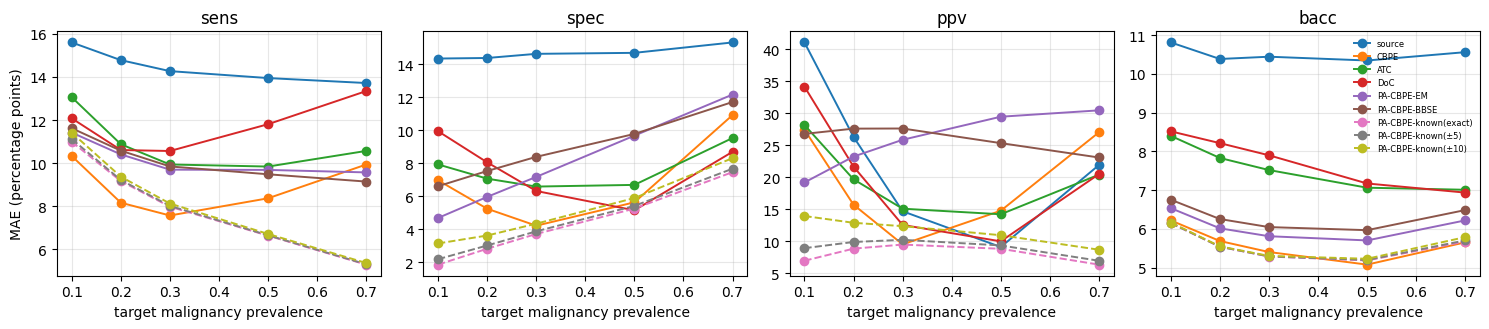

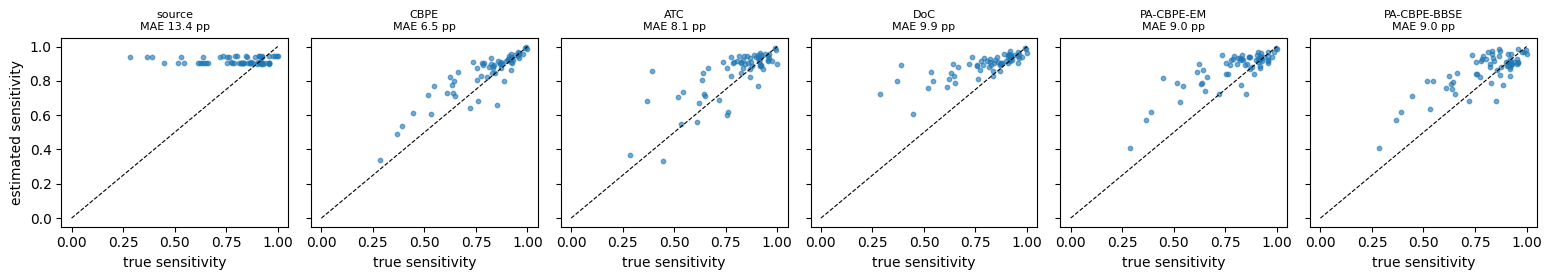


== T6 MAE (pp) vs number of labelled target cases K
K                                              0       5       10      20     40     80
metric method                                                                          
bacc   BayesRecal (proposed)                4.397   4.487   4.282   3.820  3.094  2.372
       BayesRecal from PA-CBPE (ablation)   4.767   5.875   5.015   4.265  3.281  2.434
       PPI                                    NaN  12.760   9.208   6.767  4.550  3.099
       Platt-K (no prior)                     NaN   9.526   7.408   5.377  3.736  2.620
       labels-only                            NaN  12.171   9.140   6.852  4.766  3.265
ppv    BayesRecal (proposed)                7.597  11.777   9.286   7.335  5.617  4.193
       BayesRecal from PA-CBPE (ablation)  25.470  17.954  13.469   9.722  7.003  4.809
       PPI                                    NaN  21.648  15.993  11.256  7.919  5.415
       Platt-K (no prior)                     NaN  21.246  15.494  

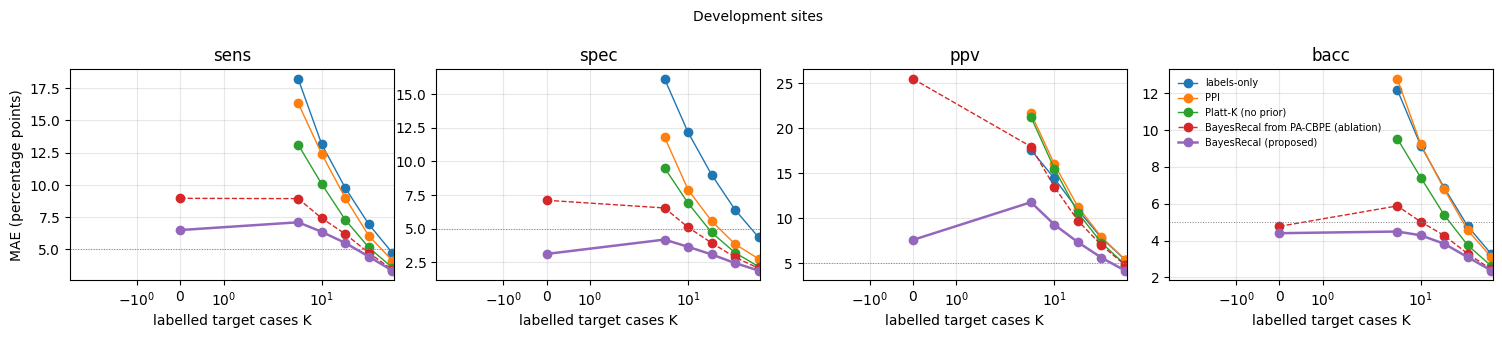


== T8 MAE (pp) vs number of unlabelled images N
N                       25      50      100     200     400
metric method                                              
bacc   ATC            9.494   7.778   6.884   6.346   6.192
       CBPE           5.237   4.771   4.559   4.443   4.014
       DoC            7.766   7.494   7.390   7.372   6.898
       PA-CBPE-BBSE   5.640   5.323   5.214   5.099   4.213
       PA-CBPE-EM     5.589   5.190   5.007   4.863   4.213
       source         9.857   9.857   9.857   9.857   9.640
ppv    ATC           16.531  14.497  13.166  12.663  10.790
       CBPE           8.920   8.233   7.798   7.673   7.170
       DoC           10.008   9.445   9.166   9.069   8.108
       PA-CBPE-BBSE  28.193  27.058  26.263  26.113  31.854
       PA-CBPE-EM    28.796  27.271  25.993  25.582  31.284
       source        10.095  10.095  10.095  10.095   9.817
sens   ATC           13.191  10.495   9.147   8.341   9.017
       CBPE           7.544   6.874   6.602   6.508

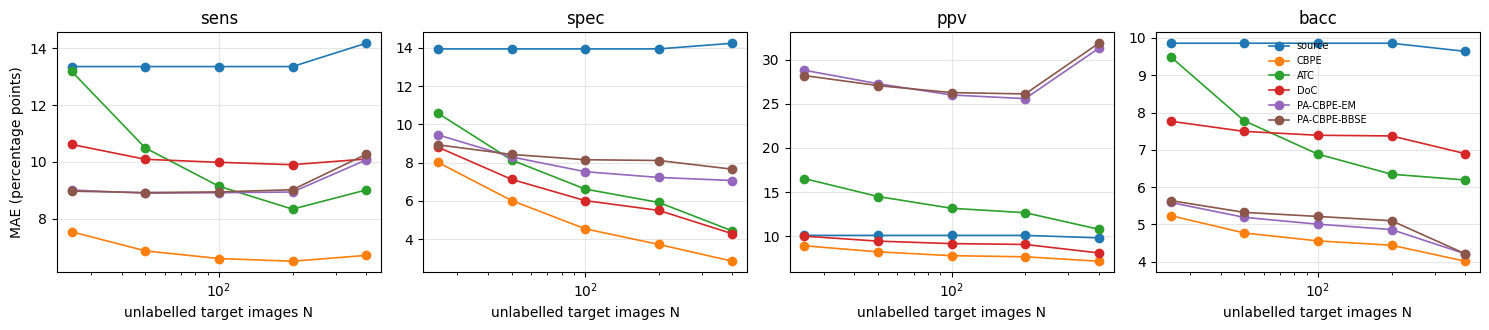


========================= CONFIRMATION: held-out site WHU =========================

== T9 [WHU] label-free MAE (pp) [95% CI]
metric                            sens             spec               ppv               npv             bacc             auroc              prev
method                                                                                                                                          
source                17.6 [13.2-22.8]  11.1 [9.2-12.9]     7.6 [5.6-9.7]  14.9 [12.7-17.9]  11.6 [8.4-14.9]  14.8 [12.8-16.8]     2.5 [1.2-4.1]
CBPE                   11.5 [8.0-15.1]    3.7 [3.0-4.3]    8.2 [6.6-10.2]  13.2 [11.6-14.7]    6.8 [4.7-9.1]   10.2 [8.0-12.1]    8.8 [7.6-10.0]
ATC                    11.1 [8.4-13.7]    5.1 [3.9-6.3]   10.1 [8.2-12.5]   11.2 [9.4-13.0]    7.7 [6.2-9.4]               n/a    8.6 [7.2-10.1]
DoC                   14.1 [10.8-17.9]    5.3 [4.2-6.4]     6.7 [5.7-7.6]  14.0 [12.0-16.3]   9.5 [7.1-11.6]               n/a     6.7 [5.4-8.3]
PA-

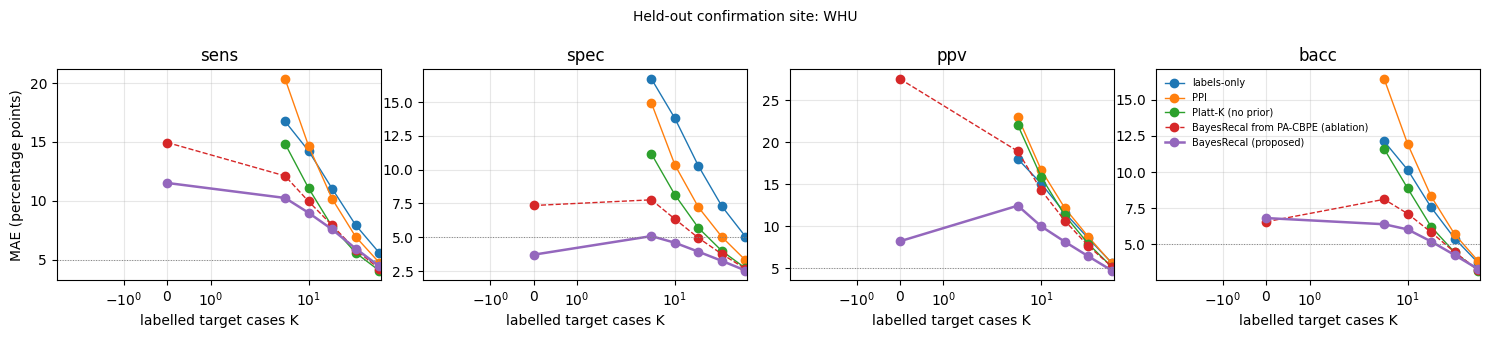


all tables/figures saved in /content/drive/MyDrive/bus_data/results


In [8]:
# ===== CELL 8: TABLES & FIGURES =====
# Two separate reports:
#   DEVELOPMENT  = deployments to the development sites (all method design decisions were made here)
#   CONFIRMATION = deployments to the untouched held-out site (CONFIG["holdout"]), evaluated once
import re
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, wilcoxon

HOLD = CONFIG.get("holdout")
FAIL_SENS = 0.85
brng = np.random.default_rng(0)
ORDER = ["source", "CBPE", "ATC", "DoC", "PA-CBPE-EM", "PA-CBPE-BBSE",
         "PA-CBPE-known(exact)", "PA-CBPE-known(±5)", "PA-CBPE-known(±10)"]
LABEL_FREE = ORDER[:6]
FL_ORDER = ["labels-only", "PPI", "Platt-K (no prior)", "BayesRecal from PA-CBPE (ablation)", "BayesRecal (proposed)"]
MAIN = ["sens", "spec", "ppv", "bacc"]
COLS_T = ["sens", "spec", "ppv", "npv", "bacc", "auroc", "prev"]


def tidy(df):
    df = df.copy()
    df["method"] = df.method.str.replace(r"known\([+-](\d+)\)", r"known(±\1)", regex=True)  # pool +e and -e
    df["role"] = np.where(df.target == HOLD, "confirmation", "development")
    if "target_prev_set" in df:
        df["target_prev_set"] = df.target_prev_set.astype(str)
    return df


def holm(p):
    """Holm-Bonferroni adjusted p-values"""
    p = np.asarray(p, float)
    o = np.argsort(p)
    adj = np.maximum.accumulate((len(p) - np.arange(len(p))) * p[o]).clip(max=1)
    out = np.empty_like(adj)
    out[o] = adj
    return out


def mae_ci(d, B=1000):
    """MAE (pp) with a 95% CI from a CLUSTER bootstrap over deployment pairs (source -> target):
    rows from the same pair (different models / repeats) are not independent, so we resample pairs."""
    per_pair = d.dropna(subset=["abs_err"]).groupby(["scenario", "source", "target"]).abs_err.mean().values * 100
    if not len(per_pair):
        return "n/a"
    bs = [brng.choice(per_pair, len(per_pair)).mean() for _ in range(B)]
    return f"{per_pair.mean():.1f} [{np.percentile(bs, 2.5):.1f}-{np.percentile(bs, 97.5):.1f}]"


def paired_tests(d, proposed, baselines, metrics, by=None, unit=("scenario", "source", "target")):
    """Wilcoxon signed-rank test of |error| (proposed vs each baseline), paired by `unit`
    (default: deployment pair, averaged over models/repeats), Holm-corrected within the table."""
    out = []
    groups = d.groupby(by) if by else [(None, d)]
    for gkey, dd in groups:
        pp = dd.groupby(["metric", "method", *unit]).abs_err.mean().unstack("method")
        for m in metrics:
            if m not in pp.index.get_level_values(0) or proposed not in pp:
                continue
            x = pp.loc[m]
            for b_ in baselines:
                if b_ not in x:
                    continue
                pair = x[[proposed, b_]].dropna()
                if len(pair) < 5 or np.allclose(pair[proposed], pair[b_]):
                    continue
                stat = wilcoxon(pair[proposed], pair[b_])
                out.append({**({by: gkey} if by else {}), "metric": m, "proposed": proposed, "vs": b_,
                            "MAE_proposed_pp": 100 * pair[proposed].mean(), "MAE_baseline_pp": 100 * pair[b_].mean(),
                            "units": len(pair), "p": stat.pvalue})
    out = pd.DataFrame(out)
    if len(out):
        out["p_holm"] = holm(out.p)
        out["significant"] = out.p_holm < 0.05
        out["winner"] = np.where(~out.significant, "no significant difference",
                                 np.where(out.MAE_proposed_pp < out.MAE_baseline_pp, "proposed", "baseline"))
    return out


def show(title, df, index=False):
    print(f"\n== {title}")
    print(df.round(3).to_string(index=index) if len(df) else "(not enough data)")


def fewlabel_curves(t6, fname, title):
    fig, axs = plt.subplots(1, 4, figsize=(15, 3.4))
    for ax, m in zip(axs, MAIN):
        for meth in FL_ORDER:
            d = t6[(t6.metric == m) & (t6.method == meth)]
            if d.MAE_pp.notna().any():
                ax.plot(d.K, d.MAE_pp, marker="o", lw=1.8 if "proposed" in meth else 1.0, label=meth,
                        ls="--" if "ablation" in meth else "-")
        ax.axhline(5, color="grey", lw=.7, ls=":")
        ax.set(title=f"{m}", xlabel="labelled target cases K", xscale="symlog")
        ax.grid(alpha=.3)
    axs[0].set_ylabel("MAE (percentage points)")
    axs[-1].legend(fontsize=7, frameon=False)
    fig.suptitle(title, fontsize=10)
    fig.tight_layout()
    fig.savefig(RESULTS / fname, dpi=200)
    plt.show()


res = tidy(pd.read_csv(RESULTS / "raw_results.csv.gz"))
fewlab = tidy(pd.read_csv(RESULTS / "raw_fewlabel.csv.gz"))
samp = tidy(pd.read_csv(RESULTS / "raw_samplesize.csv.gz"))
nat = res[res.target_prev_set == "natural"]
shift_all = nat[nat.scenario != "in-domain"]
shift = shift_all[shift_all.role == "development"]
conf = shift_all[shift_all.role == "confirmation"]
pv = res[(res.target_prev_set != "natural") & (res.role == "development")].assign(prev=lambda d: d.target_prev_set.astype(float))
fl_dev, fl_conf = fewlab[fewlab.role == "development"], fewlab[fewlab.role == "confirmation"]
print(f"development pairs: {shift.groupby(['scenario', 'source', 'target']).ngroups} | "
      f"confirmation pairs ({HOLD}): {conf.groupby(['scenario', 'source', 'target']).ngroups}")

# ============================================================== DEVELOPMENT REPORT
print("\n" + "=" * 30 + " DEVELOPMENT SITES " + "=" * 30)
# T1: how much does performance actually change at a new site?
t1 = nat[nat.method == "source"].pivot_table(index=["role", "model", "scenario", "source", "target"],
                                             columns="metric", values=["est", "true"])
t1.columns = [("source_" if a == "est" else "target_") + m for a, m in t1.columns]
t1.round(3).to_csv(RESULTS / "T1_true_performance.csv")
t1m = t1.reset_index().query("scenario != 'in-domain'").groupby("role")[
    [f"{w}_{m}" for m in ("sens", "spec", "auroc") for w in ("source", "target")]].mean()
show("T1 mean source vs target-site performance", t1m, index=True)

# T2: label-free estimation error, MAE in percentage points with 95% cluster-bootstrap CI
t2 = shift.groupby(["method", "metric"])[["scenario", "source", "target", "abs_err"]].apply(mae_ci).unstack()
t2 = t2.reindex([m for m in ORDER if m in t2.index])[COLS_T]
t2.to_csv(RESULTS / "T2_estimation_error.csv")
show("T2 MAE (pp) [95% CI], natural cross-site shift", t2, index=True)
t2c = paired_tests(shift, "CBPE", ["source", "ATC", "DoC", "PA-CBPE-EM", "PA-CBPE-BBSE"], ["sens", "spec", "ppv", "npv", "bacc"])
t2c.round(4).to_csv(RESULTS / "T2c_significance_labelfree.csv", index=False)
show("T2c CBPE (best label-free) vs others", t2c)

# T3: failure detection - does the estimate raise an alarm when true sensitivity < 0.85?
s_ = shift[shift.metric == "sens"].dropna(subset=["est", "true"]).assign(fail=lambda d: d.true < FAIL_SENS)
t3 = []
for meth, d in s_.groupby("method"):
    if meth != "source" and d.fail.nunique() == 2:
        al = d.est < FAIL_SENS
        t3.append(dict(method=meth, failures=int(d.fail.sum()), of=len(d), auroc=roc_auc_score(d.fail, -d.est),
                       alarm_sens=(al & d.fail).sum() / d.fail.sum(), alarm_spec=(~al & ~d.fail).sum() / (~d.fail).sum()))
t3 = pd.DataFrame(t3).set_index("method").reindex([m for m in ORDER if m != "source"]) if t3 else pd.DataFrame()
t3.round(3).to_csv(RESULTS / "T3_failure_detection.csv")
show(f"T3 detecting sensitivity < {FAIL_SENS}", t3, index=True)

# T4: label-free model selection - pick the best foundation model for a new site
b_ = shift[shift.metric == "bacc"].dropna(subset=["est", "true"])
t4 = []
for meth in ORDER:
    rho, reg = [], []
    for _, d in b_[b_.method == meth].groupby(["source", "target"]):
        if d.model.nunique() >= 3:
            rho.append(spearmanr(d.est, d.true).statistic)
            reg.append(d.true.max() - d.true.values[np.argmax(d.est.values)])
    if rho:
        t4.append(dict(method=meth, spearman=np.nanmean(rho), regret_pp=100 * np.mean(reg), pairs=len(rho)))
t4 = pd.DataFrame(t4).set_index("method") if t4 else pd.DataFrame()
t4.round(3).to_csv(RESULTS / "T4_model_selection.csv")
show("T4 model selection (balanced accuracy)", t4, index=True)

# T5 + F2: controlled prevalence shift; T5b: is a known (approximate) cancer rate better than CBPE?
if len(pv):
    t5 = pv.groupby(["metric", "method", "prev"]).abs_err.mean().mul(100).rename("MAE_pp").reset_index()
    t5.round(2).to_csv(RESULTS / "T5_prevalence_stress.csv", index=False)
    show("T5 MAE (pp) vs target prevalence (controlled)", t5[t5.metric.isin(MAIN + ["prev"])].pivot_table(
        index=["metric", "method"], columns="prev", values="MAE_pp"), index=True)
    t5b = paired_tests(pv, "CBPE", ["PA-CBPE-known(exact)", "PA-CBPE-known(±5)", "PA-CBPE-known(±10)"], MAIN, by="prev")
    t5b.round(4).to_csv(RESULTS / "T5b_known_prevalence_significance.csv", index=False)
    show("T5b CBPE vs prevalence-known variants, per target prevalence ('baseline' winner = known prevalence better)", t5b)
    fig, axs = plt.subplots(1, 4, figsize=(15, 3.4))
    for ax, m in zip(axs, MAIN):
        for meth in ORDER:
            d = t5[(t5.metric == m) & (t5.method == meth)]
            if d.MAE_pp.notna().any():
                ax.plot(d.prev, d.MAE_pp, marker="o", lw=1.4, label=meth, ls="--" if "known" in meth else "-")
        ax.set(title=m, xlabel="target malignancy prevalence")
        ax.grid(alpha=.3)
    axs[0].set_ylabel("MAE (percentage points)")
    axs[-1].legend(fontsize=6, frameon=False)
    fig.tight_layout()
    fig.savefig(RESULTS / "F2_prevalence_stress.png", dpi=200)
    plt.show()

# F1: estimated vs true sensitivity (label-free)
d = shift[shift.metric == "sens"]
meths = [m for m in LABEL_FREE if m in d.method.unique()]
fig, axs = plt.subplots(1, len(meths), figsize=(2.6 * len(meths), 2.9), sharex=True, sharey=True)
for ax, meth in zip(np.atleast_1d(axs), meths):
    q = d[d.method == meth]
    ax.scatter(q.true, q.est, s=10, alpha=.6)
    ax.plot([0, 1], [0, 1], "k--", lw=.8)
    ax.set_title(f"{meth}\nMAE {100 * q.abs_err.mean():.1f} pp", fontsize=8)
    ax.set_xlabel("true sensitivity")
np.atleast_1d(axs)[0].set_ylabel("estimated sensitivity")
fig.tight_layout()
fig.savefig(RESULTS / "F1_scatter_sensitivity.png", dpi=200)
plt.show()

# T6/T7/T6b/F3: few labels
t6 = fl_dev.groupby(["metric", "method", "K"]).abs_err.agg(MAE_pp=lambda x: 100 * x.mean(),
                                                           P90_pp=lambda x: 100 * x.quantile(.9)).reset_index()
t6.round(2).to_csv(RESULTS / "T6_fewlabel_error.csv", index=False)
show("T6 MAE (pp) vs number of labelled target cases K", t6[t6.metric.isin(MAIN)].pivot_table(
    index=["metric", "method"], columns="K", values="MAE_pp"), index=True)
t7 = []
for (m, meth), d in t6.groupby(["metric", "method"]):
    row = dict(metric=m, method=meth)
    for thr_pp in (5, 3):
        ok = d[d.MAE_pp < thr_pp].K
        row[f"K_for_MAE<{thr_pp}pp"] = int(ok.min()) if len(ok) else f">{d.K.max()}"
    t7.append(row)
t7 = pd.DataFrame(t7)
t7.to_csv(RESULTS / "T7_labels_needed.csv", index=False)
show("T7 labelled cases needed", t7[t7.metric.isin(MAIN)])
t6s = paired_tests(fl_dev[fl_dev.K > 0], "BayesRecal (proposed)", [m for m in FL_ORDER if "proposed" not in m], MAIN, by="K")
t6s.round(4).to_csv(RESULTS / "T6b_fewlabel_significance.csv", index=False)
show("T6b BayesRecal (proposed) vs others", t6s)
fewlabel_curves(t6, "F3_fewlabel.png", "Development sites")

# T8/F4: unlabelled sample size
t8 = samp[samp.role == "development"].groupby(["metric", "method", "N"]).abs_err.mean().mul(100).rename("MAE_pp").reset_index()
t8.round(2).to_csv(RESULTS / "T8_samplesize_error.csv", index=False)
show("T8 MAE (pp) vs number of unlabelled images N", t8[t8.metric.isin(MAIN)].pivot_table(
    index=["metric", "method"], columns="N", values="MAE_pp"), index=True)
fig, axs = plt.subplots(1, 4, figsize=(15, 3.4))
for ax, m in zip(axs, MAIN):
    for meth in LABEL_FREE:
        d = t8[(t8.metric == m) & (t8.method == meth)]
        if d.MAE_pp.notna().any():
            ax.plot(d.N, d.MAE_pp, marker="o", lw=1.2, label=meth)
    ax.set(title=m, xlabel="unlabelled target images N", xscale="log")
    ax.grid(alpha=.3)
axs[0].set_ylabel("MAE (percentage points)")
axs[-1].legend(fontsize=7, frameon=False)
fig.tight_layout()
fig.savefig(RESULTS / "F4_samplesize.png", dpi=200)
plt.show()

# ============================================================== CONFIRMATION REPORT (held-out site)
print("\n" + "=" * 25 + f" CONFIRMATION: held-out site {HOLD} " + "=" * 25)
if len(conf):
    # few deployment pairs, so tests use (deployment pair x model) as the unit
    UNIT = ("scenario", "source", "target", "model")
    t9 = conf.groupby(["method", "metric"])[["scenario", "source", "target", "abs_err"]].apply(mae_ci).unstack()
    t9 = t9.reindex([m for m in ORDER if m in t9.index])[COLS_T]
    t9.to_csv(RESULTS / "T9_confirmation_labelfree.csv")
    show(f"T9 [{HOLD}] label-free MAE (pp) [95% CI]", t9, index=True)
    t9b = paired_tests(conf, "CBPE", ["source", "ATC", "DoC", "PA-CBPE-EM", "PA-CBPE-BBSE", "PA-CBPE-known(±5)"],
                       ["sens", "spec", "ppv", "bacc"], unit=UNIT)
    t9b.round(4).to_csv(RESULTS / "T9b_confirmation_labelfree_significance.csv", index=False)
    show(f"T9b [{HOLD}] CBPE vs others", t9b)
    t10 = fl_conf.groupby(["metric", "method", "K"]).abs_err.agg(MAE_pp=lambda x: 100 * x.mean(),
                                                                  P90_pp=lambda x: 100 * x.quantile(.9)).reset_index()
    t10.round(2).to_csv(RESULTS / "T10_confirmation_fewlabel.csv", index=False)
    show(f"T10 [{HOLD}] few-label MAE (pp) vs K", t10[t10.metric.isin(MAIN)].pivot_table(
        index=["metric", "method"], columns="K", values="MAE_pp"), index=True)
    t10b = paired_tests(fl_conf[fl_conf.K > 0], "BayesRecal (proposed)", [m for m in FL_ORDER if "proposed" not in m],
                        MAIN, by="K", unit=UNIT)
    t10b.round(4).to_csv(RESULTS / "T10b_confirmation_fewlabel_significance.csv", index=False)
    show(f"T10b [{HOLD}] BayesRecal (proposed) vs others", t10b)
    fewlabel_curves(t10, "F5_confirmation_fewlabel.png", f"Held-out confirmation site: {HOLD}")
else:
    print("no held-out site in this run")
print("\nall tables/figures saved in", RESULTS)


In [9]:
# ===== CELL 9: SUPPLEMENTARY ANALYSES =====
# S1  stricter pair-level tests on the held-out site + pooled analysis over all sites
# S2  does the proposed method win for EVERY foundation model?
# S3  which target sites are hardest?
# S4  failure detection with the +/- prevalence-error variants shown separately (fixes T3 counts)
from scipy.stats import binomtest

fl = tidy(pd.read_csv(RESULTS / "raw_fewlabel.csv.gz"))
fl = fl[fl.K > 0]
PROP = "BayesRecal (proposed)"
OTHERS = [m for m in FL_ORDER if m != PROP]
PAIR = ["scenario", "source", "target"]

# ---------- S1a: held-out site, deployment pair = unit (models and repeats averaged), descriptive
rows = []
for (K, m), d in fl[fl.role == "confirmation"].groupby(["K", "metric"]):
    if m not in MAIN:
        continue
    pp = d.groupby(PAIR + ["method"]).abs_err.mean().unstack("method")
    for b in OTHERS:
        x = pp[[PROP, b]].dropna()
        wins = int((x[PROP] < x[b]).sum())
        rows.append(dict(K=K, metric=m, vs=b, pairs=len(x), proposed_better_in=f"{wins}/{len(x)}",
                         MAE_proposed_pp=100 * x[PROP].mean(), MAE_baseline_pp=100 * x[b].mean(),
                         sign_test_p=binomtest(wins, len(x)).pvalue if len(x) else np.nan))
s1a = pd.DataFrame(rows)
s1a.round(4).to_csv(RESULTS / "S1a_confirmation_pairlevel.csv", index=False)
show(f"S1a [{HOLD}] pair-level: in how many of the held-out deployment pairs does the proposed method win? "
     "(descriptive; with 9 pairs the smallest possible two-sided p is 0.004)", s1a)

# ---------- S1b: ALL sites pooled (development + held-out), deployment pair = unit, Holm-corrected
s1b = paired_tests(fl, PROP, OTHERS, MAIN, by="K")
s1b.round(4).to_csv(RESULTS / "S1b_allsites_pairlevel_significance.csv", index=False)
show("S1b all sites pooled, pair-level Wilcoxon (Holm-corrected)", s1b)

# ---------- S2: per foundation model, K = 10 and 20
rows = []
for (model, role, K, m), d in fl[fl.K.isin([10, 20]) & fl.metric.isin(MAIN)].groupby(["model", "role", "K", "metric"]):
    mae = d.groupby("method").abs_err.mean() * 100
    best_other = mae.drop(PROP).idxmin()
    rows.append(dict(model=model, role=role, K=K, metric=m, MAE_proposed_pp=mae[PROP],
                     best_alternative=best_other, MAE_best_alternative_pp=mae[best_other],
                     proposed_is_best=bool(mae[PROP] <= mae.min() + 1e-12)))
s2 = pd.DataFrame(rows)
s2.round(3).to_csv(RESULTS / "S2_per_model.csv", index=False)
show("S2 per foundation model (K = 10, 20): is the proposed method the most accurate?", s2)
print("\nproposed is best in", int(s2.proposed_is_best.sum()), "of", len(s2), "model x site-group x K x metric cells")

# ---------- S3: per target site, K = 20
s3 = (fl[(fl.K == 20) & fl.metric.isin(MAIN)].groupby(["target", "metric", "method"]).abs_err.mean().mul(100)
      .unstack("method")[FL_ORDER].round(1))
s3.to_csv(RESULTS / "S3_per_target_site_K20.csv")
show("S3 MAE (pp) per target site at K = 20", s3, index=True)

# ---------- S4: failure detection (sensitivity < FAIL_SENS), each prevalence-error direction separately
raw = pd.read_csv(RESULTS / "raw_results.csv.gz")
raw["target_prev_set"] = raw.target_prev_set.astype(str)
raw["role"] = np.where(raw.target == HOLD, "confirmation", "development")
rows = []
sv = raw[(raw.target_prev_set == "natural") & (raw.scenario != "in-domain") & (raw.metric == "sens")].dropna(subset=["est", "true"])
for (role, meth), d in sv.groupby(["role", "method"]):
    fail = d.true < FAIL_SENS
    if meth == "source" or fail.nunique() < 2:
        continue
    al = d.est < FAIL_SENS
    rows.append(dict(role=role, method=meth, failures=int(fail.sum()), of=len(d), auroc=roc_auc_score(fail, -d.est),
                     alarm_sens=(al & fail).sum() / fail.sum(), alarm_spec=(~al & ~fail).sum() / (~fail).sum()))
s4 = pd.DataFrame(rows)
s4.round(3).to_csv(RESULTS / "S4_failure_detection.csv", index=False)
show(f"S4 detecting sensitivity < {FAIL_SENS} (replaces T3; each +/- variant separately)", s4)
print("\nsupplementary tables saved in", RESULTS)



== S1a [WHU] pair-level: in how many of the held-out deployment pairs does the proposed method win? (descriptive; with 9 pairs the smallest possible two-sided p is 0.004)
 K metric                                 vs  pairs proposed_better_in  MAE_proposed_pp  MAE_baseline_pp  sign_test_p
 5   bacc                        labels-only      9                9/9            6.391           12.111        0.004
 5   bacc                                PPI      9                9/9            6.391           16.424        0.004
 5   bacc                 Platt-K (no prior)      9                9/9            6.391           11.590        0.004
 5   bacc BayesRecal from PA-CBPE (ablation)      9                9/9            6.391            8.112        0.004
 5    ppv                        labels-only      9                9/9           12.402           17.967        0.004
 5    ppv                                PPI      9                9/9           12.402           22.982        0.004
 5